# 04 - Training (Weeks 5-6)

One function, `src.train.run()`, trains any model from `src/models.py` on any split CSV and writes
`outputs/runs/<split>/<model>/` with **best.pt**, **history.csv** and **config.json**.

Training recipe (same for every model, so the comparisons are fair):
- timm ImageNet-pretrained backbone, new 4-class classifier, channels_last memory layout
- AdamW, 1 warm-up epoch, then cosine learning-rate decay
- cross-entropy with **label smoothing 0.1** and **inverse-frequency class weights** (the clean split has only ~11% notumor)
- mixed precision (float16) with a NaN guard: on this GPU float16 sometimes gives NaN, so the run falls back to float32
- up to 20 epochs, **early stopping on validation macro-F1** (patience 5); the best epoch is kept
- on CUDA out-of-memory: halve the batch and double gradient accumulation (same effective batch)
- runs that already finished are skipped, so the notebook can be stopped and restarted

**Week 6:** the light models on both the **original** split (the dataset's own folders, full of train/test duplicates)
and the **clean** split (one image per duplicate cluster). The **test** part of every split is not used here.

*Note:* the original split's validation images come from the Training folder, which contains many duplicates,
so its validation scores are expected to be inflated by leakage. The fair comparison is the test evaluation (later).

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import torch
from IPython.display import Image as ShowImage, display
from src import train
from src.models import MODELS

SPLITS = Path('outputs/splits')
RUNS = Path('outputs/runs')
print('torch', torch.__version__, '| CUDA', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
pd.DataFrame(MODELS).T

D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu126 | CUDA True | NVIDIA GeForce GTX 1650 Ti


,batch,img_size,heavy
mobilenetv3_small_100,48,224,False
efficientnet_b0,32,224,False
resnet50,24,224,True
inception_v3,24,299,True
densenet121,16,224,True
vgg16,16,224,True


## Settings
Change only this cell to choose what is trained. Runs go in this order: version -> split type -> model,
so all v1 runs finish before v2 starts. Finished runs are skipped.

In [2]:
VERSIONS = ['v1', 'v2']                                      # dataset versions
SPLIT_TYPES = ['original', 'clean']                          # outputs/splits/<version>_split_<type>.csv
MODELS_TO_RUN = ['mobilenetv3_small_100', 'efficientnet_b0']
# Maximum epochs per model. efficientnet_b0 is ~4x slower per epoch on this GPU (GPU 99% busy, measured),
# so it gets 12. The cosine LR schedule is built from this number, so the LR still decays fully to 0.
EPOCHS = {'mobilenetv3_small_100': 20, 'efficientnet_b0': 12}
# v2: mobilenet also capped at 12 to save time (decided during Week 6). v2_clean mobilenet had already
# finished with 20 (Week 5) and is skipped, so only v2_original mobilenet uses 12.
EPOCHS_V2 = {'mobilenetv3_small_100': 12, 'efficientnet_b0': 12}
PATIENCE = 5                                                 # early stopping on val macro-F1
# Stop a run as soon as val accuracy reaches this (decided during Week 6 to save time). Runs that
# finished before this setting (all mobilenet runs so far, v1_original efficientnet) did not use it.
TARGET_ACC = 0.92

## 1. Smoke test: 50 images, 1 epoch, for every model in the settings
Checks that the pipeline runs and writes its three files. The score means nothing with 50 images.
The first epoch is slow because of one-off costs (Windows DataLoader workers start up, cuDNN autotunes
its convolution algorithms for each new batch shape).

In [3]:
for model_name in MODELS_TO_RUN:
    cfg = train.run(model_name, 'smoke', SPLITS / 'v1_split_clean.csv', epochs=1, subset=50)
    smoke_dir = RUNS / 'smoke' / model_name
    h = pd.read_csv(smoke_dir / 'history.csv')
    print(f'{model_name}: files {sorted(p.name for p in smoke_dir.iterdir())}, '
          f'finite loss {h[["train_loss", "val_loss"]].notna().all().all()}, '
          f'{cfg["train_time_s"]} s, peak GPU {cfg["peak_gpu_mb"]} MB')

skipped smoke/mobilenetv3_small_100: already finished
mobilenetv3_small_100: files ['best.pt', 'config.json', 'history.csv'], finite loss True, 121.1 s, peak GPU 690.9 MB
skipped smoke/efficientnet_b0: already finished
efficientnet_b0: files ['best.pt', 'config.json', 'history.csv'], finite loss True, 150.9 s, peak GPU 2236.7 MB


Calling it again must skip the run (this is what makes stop/resume safe):

In [4]:
_ = train.run(MODELS_TO_RUN[0], 'smoke', SPLITS / 'v1_split_clean.csv', epochs=1, subset=50)

skipped smoke/mobilenetv3_small_100: already finished


## 2. Training: every model on every split in the settings
After each run: validation accuracy and macro-F1 at the best epoch, epochs run, time, peak GPU memory,
and a health check (NaN, or bad overfitting: train acc - val acc > 0.10 at the best epoch, or final val loss
25% above its minimum while train loss keeps falling).

In [5]:
run_dirs = []
for version in VERSIONS:
    for split_type in SPLIT_TYPES:
        split_name = f'{version}_{split_type}'
        for model_name in MODELS_TO_RUN:
            train.run(model_name, split_name, SPLITS / f'{version}_split_{split_type}.csv',
                      epochs=(EPOCHS_V2 if version == 'v2' else EPOCHS)[model_name], patience=PATIENCE,
                      target_acc=TARGET_ACC)
            run_dir = RUNS / split_name / model_name
            run_dirs.append(run_dir)
            s = train.run_summary(run_dir)
            print(f'==> {split_name}/{model_name}: val acc {s["val_acc"]:.4f}, val macro-F1 {s["val_macro_f1"]:.4f}, '
                  f'epochs {s["epochs_run"]} (best {s["best_epoch"]}), {s["train_time_min"]} min, '
                  f'peak GPU {s["peak_gpu_mb"]} MB')
            for w in train.health_check(run_dir):
                print('    WARNING:', w)

skipped v1_original/mobilenetv3_small_100: already finished
==> v1_original/mobilenetv3_small_100: val acc 0.9918, val macro-F1 0.9915, epochs 18 (best 13), 18.0 min, peak GPU 707.1 MB
skipped v1_original/efficientnet_b0: already finished
==> v1_original/efficientnet_b0: val acc 0.9860, val macro-F1 0.9856, epochs 9 (best 4), 44.5 min, peak GPU 2236.7 MB
skipped v1_clean/mobilenetv3_small_100: already finished
==> v1_clean/mobilenetv3_small_100: val acc 0.9808, val macro-F1 0.9809, epochs 20 (best 18), 11.2 min, peak GPU 690.9 MB
training v1_clean/efficientnet_b0 (batch 32, device cuda)


D:\Brain-Tumor\src\train.py:147: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                                  # learning rate changes after every update


  NaN/Inf with float16 at epoch 1 -> switching to float32 for the rest of the run


  epoch  1  train loss 1.6292 acc 0.6829 | val loss 1.2534 acc 0.6462 F1 0.6457 | 267.1s  *best*


  epoch  2  train loss 0.8110 acc 0.8542 | val loss 0.6531 acc 0.9077 F1 0.9051 | 211.8s  *best*


...

D:\Brain-Tumor\src\train.py:147: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                                  # learning rate changes after every update


  epoch  1  train loss 1.6584 acc 0.6747 | val loss 1.0979 acc 0.7356 F1 0.7209 | 193.4s  *best*


  epoch  2  train loss 0.8233 acc 0.8514 | val loss 0.6268 acc 0.9088 F1 0.9042 | 143.1s  *best*


  epoch  3  train loss 0.5305 acc 0.9567 | val loss 0.5377 acc 0.9479 F1 0.9432 | 142.9s  *best*
  target reached: val acc 0.9479 >= 0.92


==> v2_clean/efficientnet_b0: val acc 0.9479, val macro-F1 0.9432, epochs 3 (best 3), 8.0 min, peak GPU 1461.8 MB


## 3. Training curves of all runs in one figure
Loss axis clipped at 2.5: the epoch-1 validation loss can be ~7 because BatchNorm's running statistics lag
behind the fast-changing weights in the first epochs (checked in Week 5; not a float16 problem).

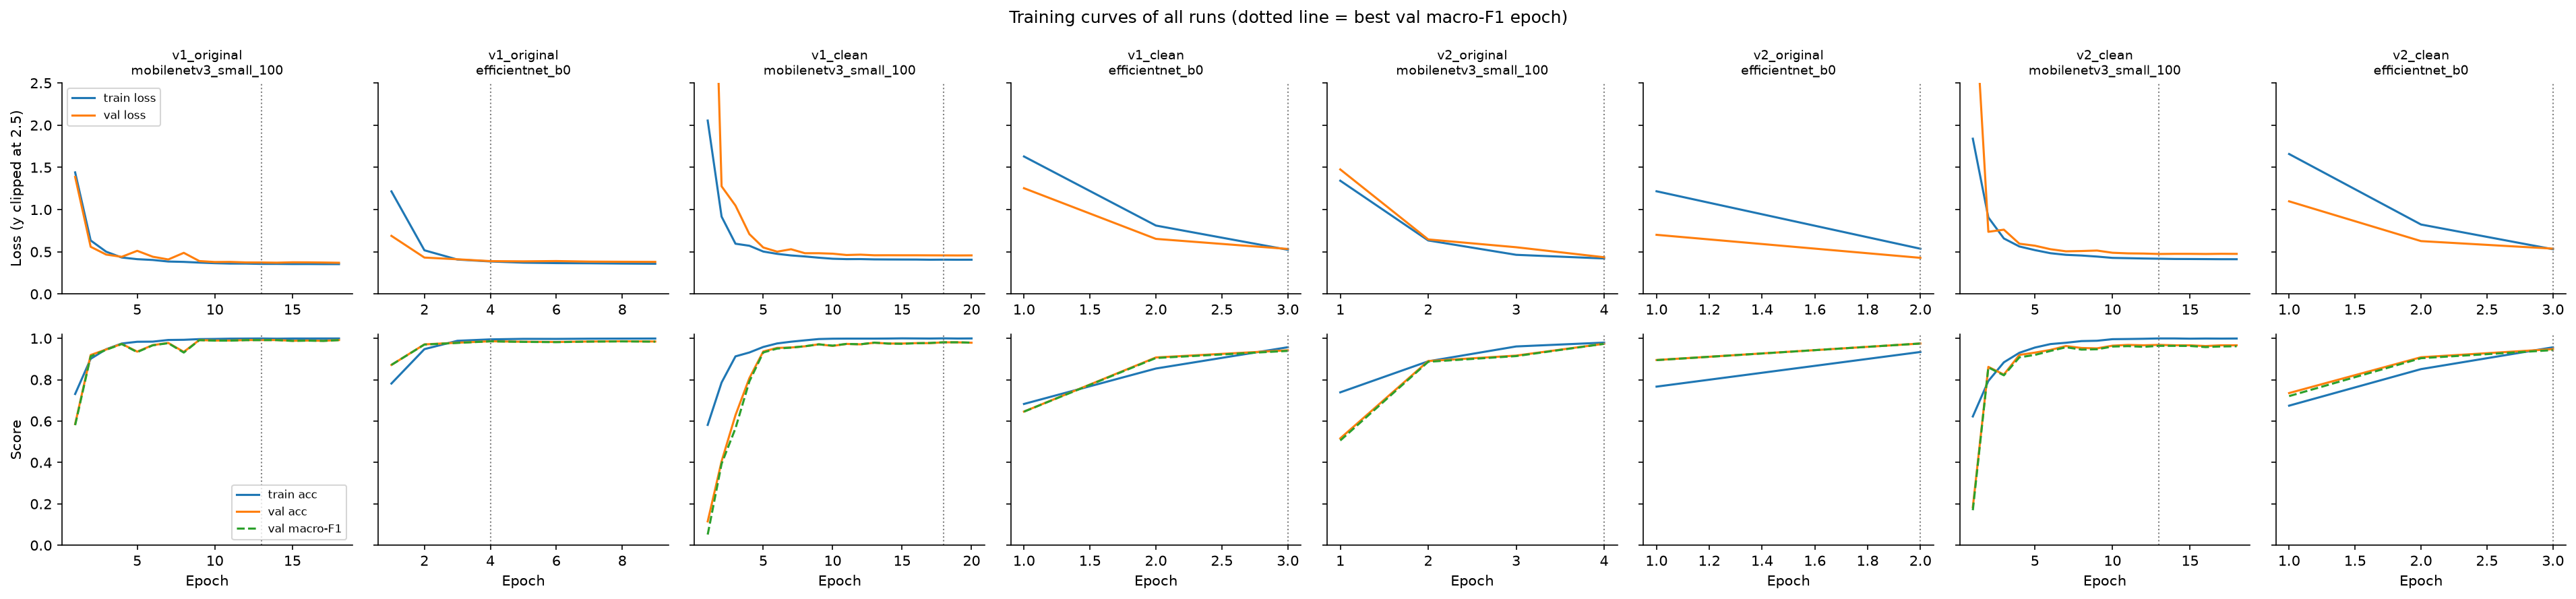

In [6]:
fig_path = train.plot_all_histories(run_dirs, 'outputs/plots/week6/all_runs_curves.png')
for run_dir in run_dirs:                                   # per-run curves are saved too (not shown)
    train.plot_history(run_dir, out_dir='outputs/plots/week6')
display(ShowImage(str(fig_path)))

## 4. Summary of all runs (validation only; test untouched)

In [7]:
summary = pd.DataFrame([train.run_summary(d) for d in run_dirs])
summary['warnings'] = [len(train.health_check(d)) for d in run_dirs]
summary

,split,model,val_acc,val_macro_f1,epochs_run,best_epoch,train_time_min,peak_gpu_mb,warnings
0,v1_original,mobilenetv3_small_100,0.9918,0.9915,18,13,18.0,707.1,0
1,v1_original,efficientnet_b0,0.9860,0.9856,9,4,44.5,2236.7,0
2,v1_clean,mobilenetv3_small_100,0.9808,0.9809,20,18,11.2,690.9,0
3,v1_clean,efficientnet_b0,0.9423,0.9394,3,3,10.8,3082.0,1
4,v2_original,mobilenetv3_small_100,0.9738,0.9736,4,4,5.3,707.1,0
5,v2_original,efficientnet_b0,0.9750,0.9750,2,2,11.2,2794.8,1
6,v2_clean,mobilenetv3_small_100,0.9683,0.9639,18,13,8.9,453.5,0
7,v2_clean,efficientnet_b0,0.9479,0.9432,3,3,8.0,1461.8,0
